# Clustering

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")
%matplotlib inline

In [2]:
iris_df=sns.load_dataset("iris")

In [3]:
iris_df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


<Axes: xlabel='sepal_width', ylabel='petal_width'>

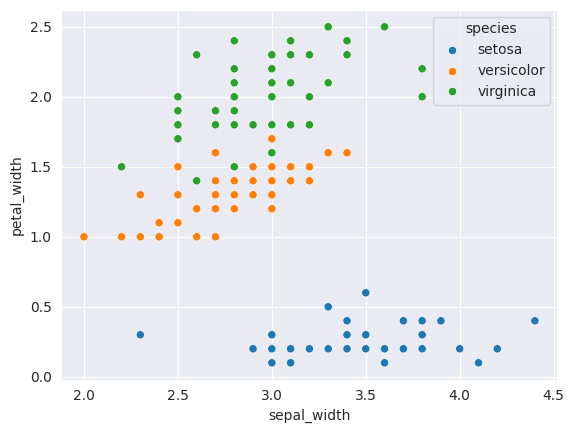

In [4]:
sns.scatterplot(iris_df,x="sepal_width",y="petal_width",hue="species")

<Axes: xlabel='sepal_length', ylabel='petal_length'>

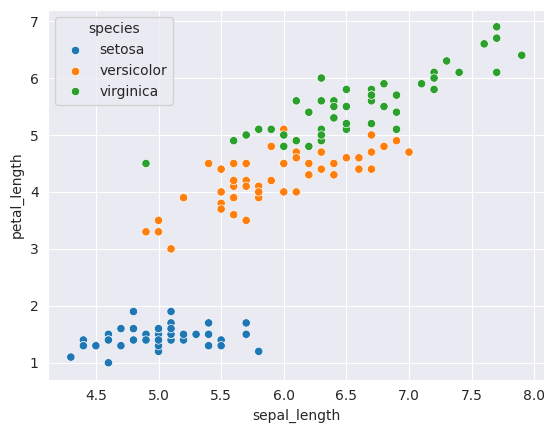

In [5]:
sns.scatterplot(iris_df,x="sepal_length",y="petal_length",hue="species")

In [6]:
numerical_cols=iris_df.select_dtypes(include=np.number).columns.to_list()

In [7]:
x=iris_df[numerical_cols]

 K_Meansclustering

In [8]:
from sklearn.cluster import KMeans

In [9]:
model=KMeans(n_clusters=3,random_state=42)

In [10]:
model.fit(x)

KMeans(n_clusters=3, random_state=42)

In [11]:
model.cluster_centers_

array([[6.85384615, 3.07692308, 5.71538462, 2.05384615],
       [5.006     , 3.428     , 1.462     , 0.246     ],
       [5.88360656, 2.74098361, 4.38852459, 1.43442623]])

In [12]:
preds=model.predict(x)
preds

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 2, 2, 0, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 2], dtype=int32)

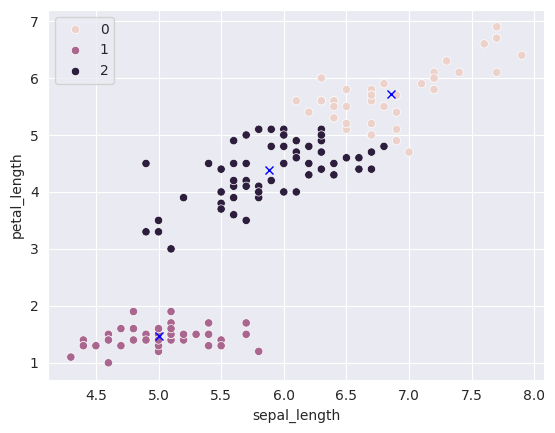

In [13]:
sns.scatterplot(data=x,x="sepal_length",y="petal_length",hue=preds);
center_x,center_y=model.cluster_centers_[:,0],model.cluster_centers_[:,2]
plt.plot(center_x,center_y,"xb")

In [14]:
model.inertia_

78.85566582597727

In [15]:
model=KMeans(n_clusters=6,random_state=42)

In [16]:
model.fit(x)

KMeans(n_clusters=6, random_state=42)

In [17]:
preds=model.predict(x)
preds

array([1, 5, 5, 5, 1, 1, 5, 1, 5, 5, 1, 5, 5, 5, 1, 1, 1, 1, 1, 1, 1, 1,
       5, 1, 5, 5, 1, 1, 1, 5, 5, 1, 1, 1, 5, 5, 1, 1, 5, 1, 1, 5, 5, 1,
       1, 5, 1, 5, 1, 5, 0, 0, 0, 2, 0, 2, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0,
       2, 2, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 0, 2, 0, 0, 0,
       2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 4, 0, 3, 4, 4, 3, 2, 3, 4, 3,
       4, 4, 4, 0, 4, 4, 4, 3, 3, 0, 4, 0, 3, 0, 4, 3, 0, 0, 4, 3, 3, 3,
       4, 0, 0, 3, 4, 4, 0, 4, 4, 4, 0, 4, 4, 4, 0, 4, 4, 0], dtype=int32)

<Axes: xlabel='sepal_width', ylabel='petal_width'>

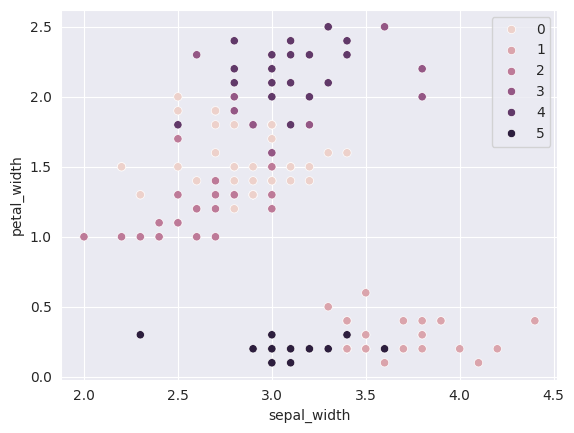

In [18]:
sns.scatterplot(data=x,x="sepal_width",y="petal_width",hue=preds)

In [19]:
model.inertia_

39.066035353535376

Text(0.5, 0, 'No of clusters (k)')

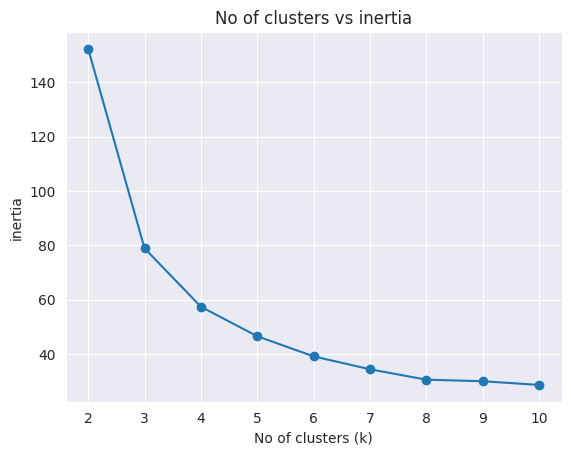

In [20]:
options=range(2,11)
inertias=[]
for n_cluster in options:
  model=KMeans(n_clusters=n_cluster,random_state=42)
  model.fit_predict(x)
  inertias.append(model.inertia_)
plt.title("No of clusters vs inertia")
plt.plot(options,inertias,"-o")
plt.ylabel("inertia")
plt.xlabel("No of clusters (k)")

so in this case the best one could be 6 or 5

---



# Mini-Batch-K-means

In [21]:
from sklearn.cluster import MiniBatchKMeans


In [22]:
mb_kmeans=MiniBatchKMeans(
    n_clusters=3,
    batch_size=25,
    random_state=42,
    n_init="auto"
)

In [23]:
model=mb_kmeans.fit(x)
preds=model.predict(x)
preds

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [24]:
model.inertia_

81.21031200052089

In [25]:
x

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [26]:
model.cluster_centers_

array([[6.73055556, 3.03666667, 5.60611111, 2.04944444],
       [5.00063694, 3.44394904, 1.4656051 , 0.24076433],
       [5.76808511, 2.70957447, 4.21223404, 1.37287234]])

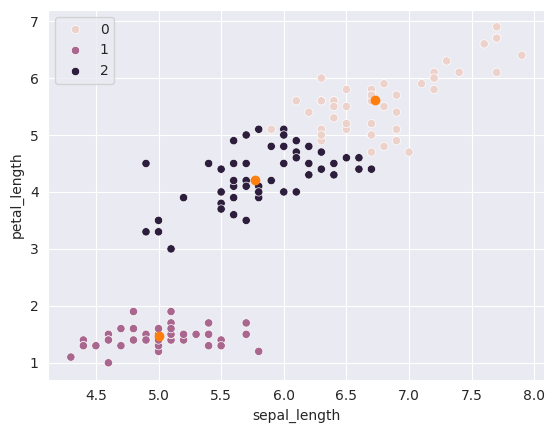

In [27]:
sns.scatterplot(data=x,x="sepal_length",y="petal_length",hue=preds)
center_x,center_y=model.cluster_centers_[:,0],model.cluster_centers_[:,2]
plt.scatter(center_x,center_y)

In [28]:
?KMeans

# DBSCAN

In [29]:
from sklearn.cluster import DBSCAN

In [30]:
?DBSCAN

In [31]:
model=DBSCAN(eps=1,min_samples=4)
model.fit(x)

DBSCAN(eps=1, min_samples=4)

In [32]:
label=model.labels_

<Axes: xlabel='sepal_length', ylabel='petal_length'>

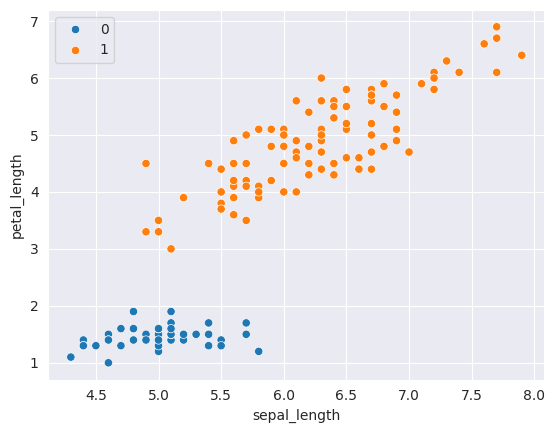

In [33]:
sns.scatterplot(data=x,x="sepal_length",y="petal_length",hue=label)

In [34]:
dir(model)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_estimator_type',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_tags',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_validate_data',
 '_validate_params',
 'algorithm',
 'components_',
 'core_sample_indices_',
 'eps',
 'feature_names_in_',
 'fit',
 'fit_predict',


# Hierarchical Clustering

In [35]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage
from sklearn.datasets import load_iris

In [36]:
X=load_iris()

In [37]:
model=AgglomerativeClustering(n_clusters=3,linkage="ward")
model.fit(x)


AgglomerativeClustering(n_clusters=3)

In [38]:
model.n_clusters_

3

In [39]:
label=model.labels_

<Axes: xlabel='sepal_length', ylabel='petal_length'>

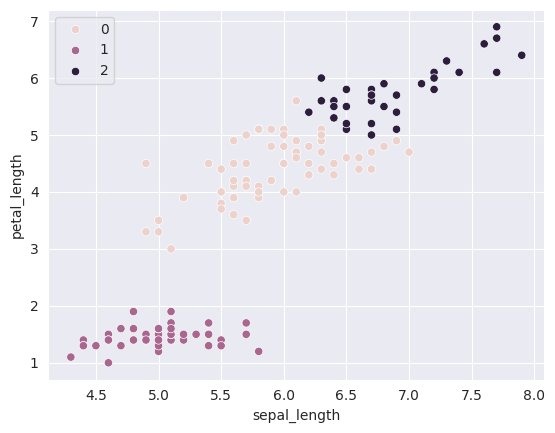

In [40]:
sns.scatterplot(data=x,x="sepal_length",y="petal_length",hue=label)

<Axes: xlabel='sepal_length', ylabel='petal_length'>

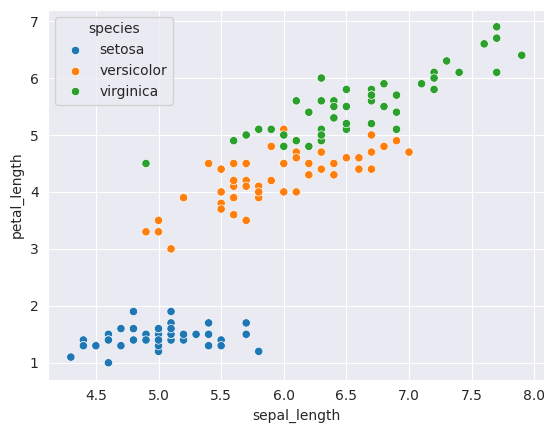

In [41]:
sns.scatterplot(data=iris_df, x="sepal_length",y="petal_length",hue="species")

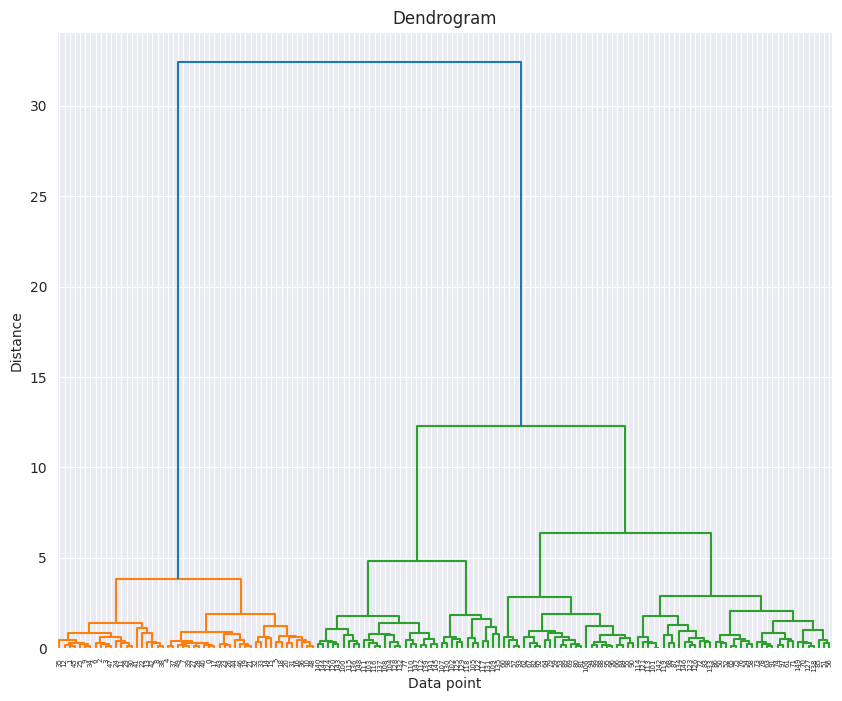

In [42]:
linked=linkage(x,method="ward")
plt.figure(figsize=(10,8))
dendrogram(linked)
plt.title("Dendrogram")
plt.ylabel("Distance")
plt.xlabel("Data point")
plt.show()

# Dimension Reduction and mainfold Learning

In [43]:
iris_df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [44]:
from sklearn.decomposition import PCA

In [45]:
?PCA

In [46]:
pca=PCA(n_components=2)

In [47]:
dir(PCA)

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_fit',
 '_fit_full',
 '_fit_truncated',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_tags',
 '_more_tags',
 '_n_features_out',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_sklearn_auto_wrap_output_keys',
 '_transform',
 '_validate_data',


In [48]:
pca.fit(iris_df[numerical_cols])

PCA(n_components=2)

In [49]:
pca.components_

array([[ 0.36138659, -0.08452251,  0.85667061,  0.3582892 ],
       [ 0.65658877,  0.73016143, -0.17337266, -0.07548102]])

In [50]:
transformed =pca.transform(iris_df[numerical_cols])

<Axes: >

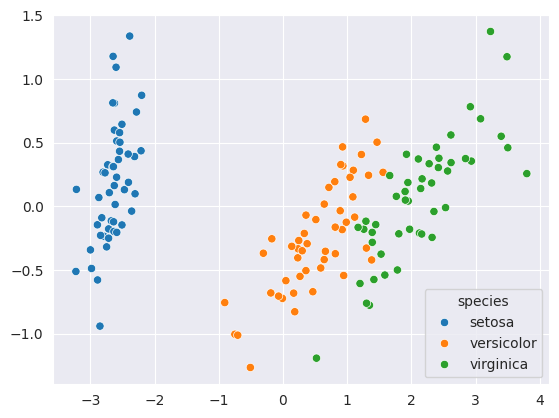

In [51]:
sns.scatterplot(x=transformed[:,0],y=transformed[:,1],hue=iris_df["species"])

# T-distributed stoichastic Neighbor embedding(t-sne)

In [52]:
from sklearn.manifold import TSNE

In [53]:
?TSNE

In [54]:
tsne=TSNE(n_components=2)

In [57]:
transformed=tsne.fit_transform(iris_df[numerical_cols])

In [59]:
transformed

array([[-2.42846699e+01, -1.96068853e-01],
       [-2.17319050e+01,  6.53882325e-01],
       [-2.17767735e+01, -4.33847994e-01],
       [-2.14130859e+01, -1.41203120e-01],
       [-2.42849083e+01, -6.06253624e-01],
       [-2.62441120e+01, -5.33888757e-01],
       [-2.20059872e+01, -7.92660773e-01],
       [-2.36063728e+01,  8.98885578e-02],
       [-2.08891449e+01, -8.28106523e-01],
       [-2.22197151e+01,  4.80458289e-01],
       [-2.58226967e+01,  8.83378163e-02],
       [-2.29560204e+01,  3.29243898e-01],
       [-2.14609852e+01,  4.00310963e-01],
       [-2.04171238e+01, -7.15105116e-01],
       [-2.71277199e+01,  4.87351343e-02],
       [-2.72579269e+01, -4.86495912e-01],
       [-2.64031487e+01, -2.06707284e-01],
       [-2.43507843e+01, -6.94209263e-02],
       [-2.66233368e+01,  3.07076067e-01],
       [-2.53120079e+01, -6.81390285e-01],
       [-2.52586861e+01,  9.00316954e-01],
       [-2.50500813e+01, -4.59083408e-01],
       [-2.02292347e+01,  2.96012908e-01],
       [-2.

<Axes: >

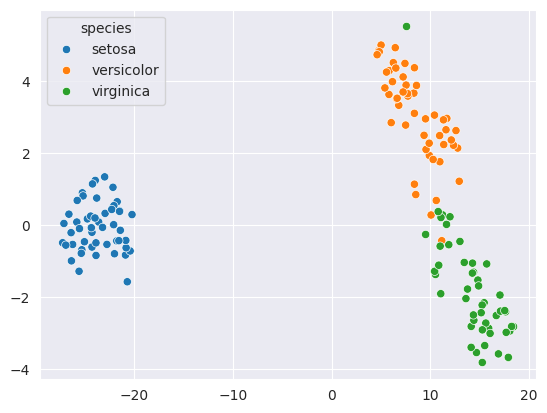

In [58]:
sns.scatterplot(x=transformed[:,0],y=transformed[:,1],hue=iris_df["species"])